# Ejercicio 3: Predicción del consumo de energía eléctrica

**Laboratorio 1 – Minería de Datos** · Regresión lineal múltiple siguiendo la metodología **CRISP-DM**

Dataset: `data/energia_data.csv` · Variable dependiente: `Consumo_Energia`

**Contenido**
1. Comprensión del negocio
2. Comprensión de los datos (EDA)
3. Preparación de los datos
4. Modelado
5. Evaluación
6. Análisis adicional: la hora como variable cíclica
7. Despliegue: exportación del modelo
8. Conclusiones

## 1. Comprensión del negocio

**Contexto.** Las empresas de energía necesitan anticipar el consumo para planear la generación y evitar sobrecargas. El consumo cambia con el clima, la hora y el día.

**Objetivo de minería de datos.** Construir un modelo de **regresión lineal múltiple** que prediga `Consumo_Energia` a partir de:

| Variable | Descripción | Rol |
|---|---|---|
| `Temperatura` | Temperatura en °C | Independiente |
| `Hora` | Hora del día (1 a 24, cíclica) | Independiente |
| `Dia_Semana` | Día de la semana (1 = lunes ... 7 = domingo) | Independiente |
| `Consumo_Energia` | Consumo en kWh | **Dependiente** |

**Preguntas a responder.**
1. **¿Qué variable tiene mayor impacto en el consumo?**
2. ¿Qué tan bien predice el modelo? (**RMSE** y R², como pide el enunciado)
3. ¿Cuáles son las relaciones más importantes? (dispersión y correlación)

**Criterio de éxito.** Un R² alto en prueba y un RMSE pequeño frente al consumo promedio.

### Librerías y configuración

In [1]:
import json
import pickle
from pathlib import Path

import joblib
import matplotlib.pyplot as plt
import numpy as np
import pandas as pd
import seaborn as sns
import sklearn
import statsmodels.api as sm
from matplotlib.colors import LinearSegmentedColormap
from matplotlib.lines import Line2D
from sklearn.linear_model import LinearRegression
from sklearn.metrics import mean_squared_error, r2_score
from sklearn.model_selection import train_test_split

# Rutas del proyecto (funciona ejecutando desde notebooks/ o desde la raíz)
BASE = Path.cwd() if (Path.cwd() / "data").exists() else Path.cwd().parent
DATA = BASE / "data"
FIGURAS = BASE / "informe" / "figuras"
MODELOS = BASE / "modelos"
FIGURAS.mkdir(parents=True, exist_ok=True)
MODELOS.mkdir(parents=True, exist_ok=True)

# Configuración del ejercicio
NOMBRE = "energia"
OBJETIVO = "Consumo_Energia"
VARIABLES = ['Temperatura', 'Hora', 'Dia_Semana']
ETIQUETAS = {'Temperatura': 'Temperatura (°C)', 'Hora': 'Hora del día (1 a 24)', 'Dia_Semana': 'Día de la semana (1 = lunes ... 7 = domingo)', 'Consumo_Energia': 'Consumo de energía (kWh)'}
UNIDAD_Y = "kWh"
SEMILLA = 42

# Estilo de las gráficas
AZUL, NARANJA, AQUA, ROJO = "#2a78d6", "#eb6834", "#1baf7a", "#e34948"
TEXTO, TEXTO_SEC, REJILLA = "#0b0b0b", "#52514e", "#e6e5e0"
plt.rcParams.update({
    "figure.facecolor": "white", "axes.facecolor": "white",
    "axes.edgecolor": REJILLA, "axes.labelcolor": TEXTO_SEC,
    "axes.titlecolor": TEXTO, "axes.titlesize": 11, "axes.titleweight": "bold",
    "axes.spines.top": False, "axes.spines.right": False,
    "axes.grid": True, "axes.axisbelow": True, "grid.color": REJILLA, "grid.linewidth": 0.8,
    "xtick.color": TEXTO_SEC, "ytick.color": TEXTO_SEC,
    "legend.frameon": False, "font.size": 10, "savefig.dpi": 150,
})
CMAP_DIVERGENTE = LinearSegmentedColormap.from_list("azul_rojo", [AZUL, "#f0efec", ROJO])


def guardar(fig, nombre):
    """Guarda la figura como PNG en informe/figuras/."""
    ruta = FIGURAS / f"{NOMBRE}_{nombre}.png"
    fig.savefig(ruta, bbox_inches="tight")
    print("Figura guardada:", ruta.relative_to(BASE))


def fmt_p(p):
    """Muestra un p-valor de forma legible."""
    return "< 0.001" if p < 0.001 else f"= {p:.3f}"


pd.set_option("display.float_format", lambda v: f"{v:,.4f}")

## 2. Comprensión de los datos (EDA)

### 2.1 Carga y estructura

In [2]:
df = pd.read_csv(DATA / f"{NOMBRE}_data.csv")
print("Filas y columnas:", df.shape)
df.head()

Filas y columnas: (10000, 4)


,Temperatura,Hora,Dia_Semana,Consumo_Energia
0,28.8918,1,1,401.9906
1,22.2441,2,2,334.8469
2,20.9090,3,3,326.9261
3,24.9831,4,4,383.0170
4,24.1491,5,5,388.7482


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 10000 entries, 0 to 9999
Data columns (total 4 columns):
 #   Column           Non-Null Count  Dtype  
---  ------           --------------  -----  
 0   Temperatura      10000 non-null  float64
 1   Hora             10000 non-null  int64  
 2   Dia_Semana       10000 non-null  int64  
 3   Consumo_Energia  10000 non-null  float64
dtypes: float64(2), int64(2)
memory usage: 312.6 KB


### 2.2 Estadísticas descriptivas y rangos

In [4]:
df.describe().T

,count,mean,std,min,25%,50%,75%,max
Temperatura,"10,000.0000",24.9248,5.0040,5.3880,21.5785,24.9005,28.3110,44.6312
Hora,"10,000.0000",12.4936,6.9213,1.0000,6.0000,12.0000,18.0000,24.0000
Dia_Semana,"10,000.0000",3.9994,2.0000,1.0000,2.0000,4.0000,6.0000,7.0000
Consumo_Energia,"10,000.0000",400.0435,63.8252,185.1964,356.7353,399.2704,443.1341,631.0932


### 2.3 Calidad de los datos: nulos, duplicados y atípicos

In [5]:
print("Valores nulos por columna:")
print(df.isna().sum().to_string())
print("\nFilas duplicadas:", df.duplicated().sum())

Valores nulos por columna:
Temperatura        0
Hora               0
Dia_Semana         0
Consumo_Energia    0

Filas duplicadas: 0


In [6]:
# Valores atípicos con la regla del rango intercuartílico (IQR)
q1, q3 = df.quantile(0.25), df.quantile(0.75)
iqr = q3 - q1
lim_inf, lim_sup = q1 - 1.5 * iqr, q3 + 1.5 * iqr
atipicos = ((df < lim_inf) | (df > lim_sup)).sum()
pd.DataFrame({
    "limite_inferior": lim_inf, "limite_superior": lim_sup,
    "minimo": df.min(), "maximo": df.max(),
    "n_atipicos": atipicos, "porcentaje": 100 * atipicos / len(df),
})

,limite_inferior,limite_superior,minimo,maximo,n_atipicos,porcentaje
Temperatura,11.4799,38.4096,5.3880,44.6312,90,0.9000
Hora,-12.0000,36.0000,1.0000,24.0000,0,0.0000
Dia_Semana,-4.0000,12.0000,1.0000,7.0000,0,0.0000
Consumo_Energia,227.1370,572.7323,185.1964,631.0932,66,0.6600


**Hallazgos de la revisión de calidad**

- El dataset tiene **10 000 filas y 4 columnas**, todas numéricas. `Hora` toma los enteros de 1 a 24 y `Dia_Semana` de 1 a 7, ambos repartidos de forma pareja.
- **No hay valores nulos ni filas duplicadas.**
- Con la regla IQR aparecen **90 valores atípicos en `Temperatura`** (0.9 %) y **66 en `Consumo_Energia`** (0.66 %). Son temperaturas entre 5.4 y 44.6 °C y consumos entre 185 y 631 kWh: valores extremos pero físicamente posibles. **Se conservan**: son las colas normales de la distribución, no errores.
- El consumo promedio es de 400.0 kWh.

### 2.4 Distribución de las variables

Figura guardada: informe/figuras/energia_distribuciones.png


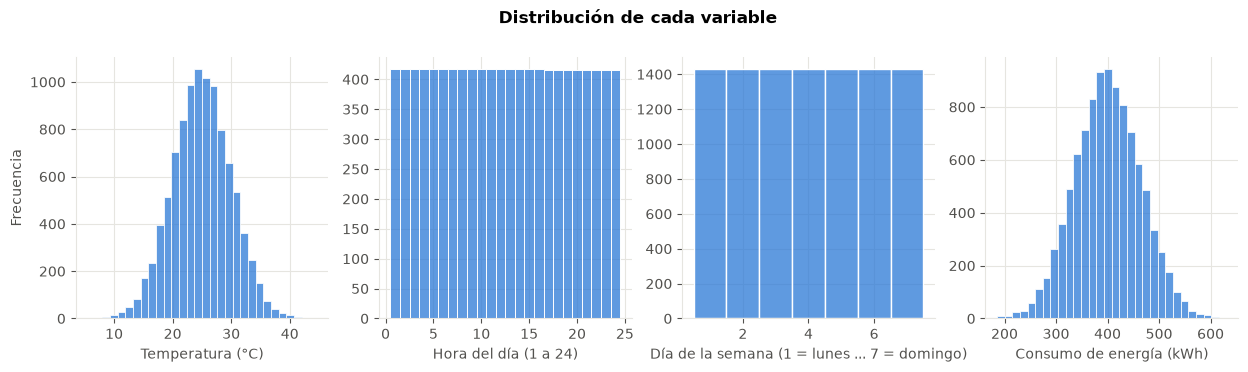

In [7]:
fig, ejes = plt.subplots(1, len(df.columns), figsize=(15, 3.4))
for ax, col in zip(ejes, df.columns):
    discreta = df[col].nunique() < 30
    sns.histplot(df[col], ax=ax, color=AZUL, edgecolor="white", discrete=discreta, bins="auto" if discreta else 30)
    ax.set_xlabel(ETIQUETAS[col])
    ax.set_ylabel("Frecuencia" if ax is ejes[0] else "")
fig.suptitle("Distribución de cada variable", fontweight="bold", y=1.02)
guardar(fig, "distribuciones")
plt.show()

### 2.5 Matriz de correlación

Figura guardada: informe/figuras/energia_correlacion.png


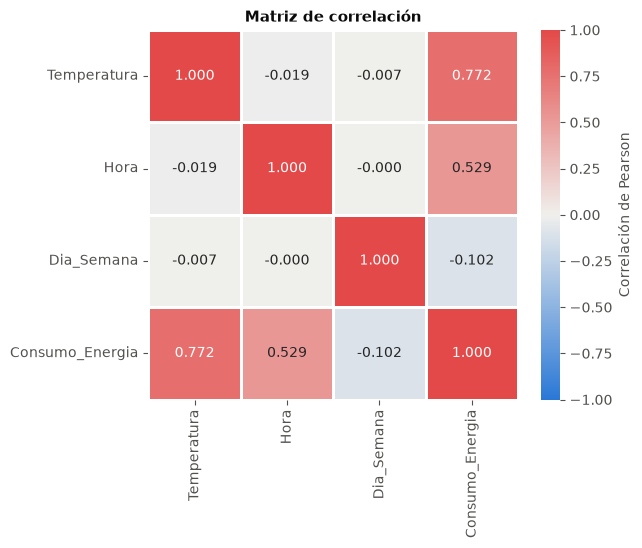

,Correlación con Consumo_Energia
Temperatura,0.7719
Hora,0.5290
Dia_Semana,-0.1022


In [8]:
corr = df.corr()
fig, ax = plt.subplots(figsize=(6, 4.8))
sns.heatmap(corr, annot=True, fmt=".3f", cmap=CMAP_DIVERGENTE, vmin=-1, vmax=1, center=0,
            linewidths=2, linecolor="white", square=True, ax=ax,
            cbar_kws={"label": "Correlación de Pearson"})
ax.set_title("Matriz de correlación")
ax.grid(False)
guardar(fig, "correlacion")
plt.show()

corr[OBJETIVO].drop(OBJETIVO).to_frame("Correlación con " + OBJETIVO)

**Lectura de la matriz de correlación**

- `Temperatura` es la variable más relacionada con el consumo (**r = 0.772**).
- `Hora` tiene una correlación positiva moderada (**0.529**).
- `Dia_Semana` tiene una correlación negativa débil (−0.102).
- Las variables independientes no se relacionan entre sí (correlaciones menores a 0.02): **no hay multicolinealidad**.

### 2.6 Relación de cada variable independiente con `Consumo_Energia`

Figura guardada: informe/figuras/energia_dispersion.png


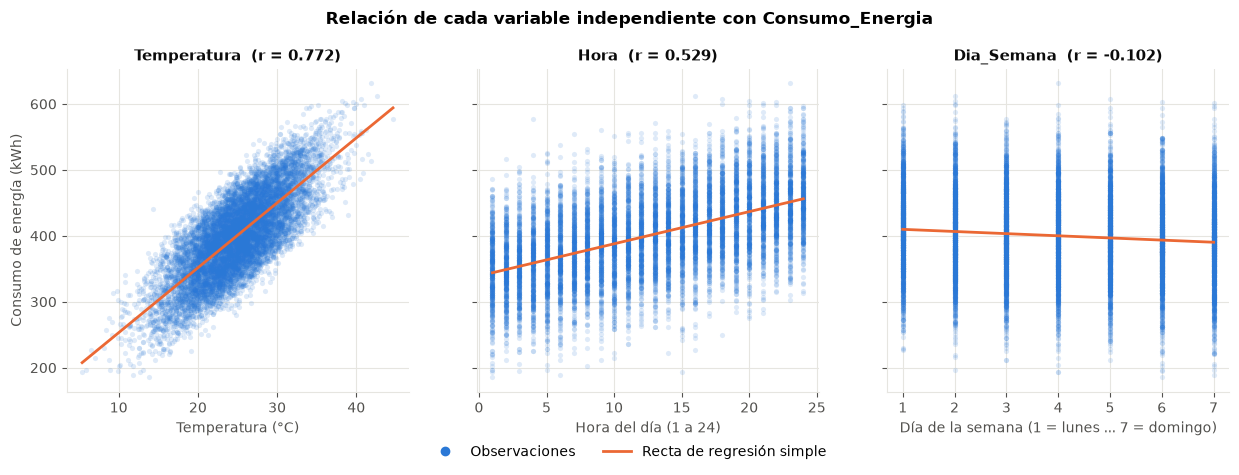

In [9]:
alfa = max(0.15, min(0.7, 600 / len(df)))
fig, ejes = plt.subplots(1, len(VARIABLES), figsize=(15, 4.2), sharey=True)
for ax, var in zip(ejes, VARIABLES):
    ax.scatter(df[var], df[OBJETIVO], s=14, color=AZUL, alpha=alfa, linewidths=0)
    pendiente, corte = np.polyfit(df[var], df[OBJETIVO], 1)
    xs = np.linspace(df[var].min(), df[var].max(), 100)
    ax.plot(xs, pendiente * xs + corte, color=NARANJA, linewidth=2)
    ax.set_title(f"{var}  (r = {df[var].corr(df[OBJETIVO]):.3f})")
    ax.set_xlabel(ETIQUETAS[var])
ejes[0].set_ylabel(ETIQUETAS[OBJETIVO])
fig.legend(handles=[
    Line2D([], [], marker="o", linestyle="", color=AZUL, label="Observaciones"),
    Line2D([], [], color=NARANJA, linewidth=2, label="Recta de regresión simple"),
], loc="lower center", ncol=2, bbox_to_anchor=(0.5, -0.08))
fig.suptitle(f"Relación de cada variable independiente con {OBJETIVO}", fontweight="bold", y=1.02)
guardar(fig, "dispersion")
plt.show()

**Lectura de las gráficas de dispersión.** La línea naranja de cada panel es una regresión *simple* (una sola variable).

- **Temperatura:** relación ascendente muy marcada; es la relación más importante del ejercicio.
- **Hora:** el consumo aumenta a lo largo del día, de la hora 1 a la 24.
- **Dia_Semana:** pendiente ligeramente negativa; el consumo baja un poco hacia el fin de semana.

`Hora` y `Dia_Semana` forman columnas porque solo toman valores enteros.

## 3. Preparación de los datos

- **Limpieza:** se eliminan nulos y duplicados. En este dataset no hay ninguno, pero el paso se deja en el código para que el proceso sea reproducible con datos nuevos.
- **Atípicos:** se conservan, por las razones explicadas en la sección 2.3.
- **Escalado:** no es necesario. La regresión lineal por mínimos cuadrados da las mismas predicciones con o sin escalar, y sin escalar los coeficientes quedan en las unidades originales, lo que facilita interpretarlos.
- **División:** 80 % para entrenamiento y 20 % para prueba, con `random_state=42` para que el resultado sea reproducible.

In [10]:
# Limpieza: se eliminan nulos y duplicados (si los hubiera) y se verifica el resultado
filas_antes = len(df)
df = df.dropna().drop_duplicates().reset_index(drop=True)
print(f"Filas antes: {filas_antes} | filas después de la limpieza: {len(df)}")

X = df[VARIABLES]
y = df[OBJETIVO]

# División 80 % entrenamiento / 20 % prueba
X_train, X_test, y_train, y_test = train_test_split(X, y, test_size=0.2, random_state=SEMILLA)
print("Entrenamiento:", X_train.shape, "| Prueba:", X_test.shape)

Filas antes: 10000 | filas después de la limpieza: 10000
Entrenamiento: (8000, 3) | Prueba: (2000, 3)


## 4. Modelado

Se ajusta un modelo de **regresión lineal múltiple** con `LinearRegression` de scikit-learn, usando solo los datos de entrenamiento. El modelo busca la ecuación

$$\hat{y} = \beta_0 + \beta_1 x_1 + \beta_2 x_2 + \beta_3 x_3$$

que minimiza la suma de los errores al cuadrado (mínimos cuadrados ordinarios).

In [11]:
modelo = LinearRegression()
modelo.fit(X_train, y_train)

coeficientes = pd.Series(modelo.coef_, index=VARIABLES, name="Coeficiente")
print(f"Intercepto: {modelo.intercept_:,.4f}")
display(coeficientes.to_frame())

ecuacion = f"{OBJETIVO} = {modelo.intercept_:.4f}" + "".join(
    f" {'+' if c >= 0 else '-'} {abs(c):.4f}*{v}" for v, c in coeficientes.items())
print("Ecuación del modelo:")
print(ecuacion)

Intercepto: 101.2882


,Coeficiente
Temperatura,9.9529
Hora,5.0198
Dia_Semana,-3.0312


Ecuación del modelo:
Consumo_Energia = 101.2882 + 9.9529*Temperatura + 5.0198*Hora - 3.0312*Dia_Semana


## 5. Evaluación

### 5.1 Métricas de desempeño

- **MSE** (error cuadrático medio): promedio de los errores al cuadrado. Cuanto más bajo, mejor.
- **RMSE**: raíz del MSE; queda en las mismas unidades de la variable dependiente.
- **R²** (coeficiente de determinación): proporción de la variación de la variable dependiente que explica el modelo (1 = ajuste perfecto).

Se calculan en entrenamiento y en prueba para detectar un posible sobreajuste.

In [12]:
def calcular_metricas(y_real, y_pred):
    mse = mean_squared_error(y_real, y_pred)
    return {"MSE": mse, "RMSE": np.sqrt(mse), "R2": r2_score(y_real, y_pred)}


pred_train = modelo.predict(X_train)
pred_test = modelo.predict(X_test)
metricas = {
    "entrenamiento": calcular_metricas(y_train, pred_train),
    "prueba": calcular_metricas(y_test, pred_test),
}
tabla_metricas = pd.DataFrame(metricas).T
print(f"Media de {OBJETIVO}: {y.mean():,.2f} {UNIDAD_Y}")
print(f"RMSE de prueba como % de la media: {100 * metricas['prueba']['RMSE'] / y.mean():.2f} %")
tabla_metricas

Media de Consumo_Energia: 400.04 kWh
RMSE de prueba como % de la media: 5.18 %


,MSE,RMSE,R2
entrenamiento,399.1937,19.9798,0.9015
prueba,429.5187,20.7248,0.8968


**Interpretación del desempeño** (el enunciado pide RMSE y R²)

| Conjunto | RMSE | R² | MSE |
|---|---|---|---|
| Entrenamiento | 19.98 | 0.9015 | 399.19 |
| Prueba | 20.72 | 0.8968 | 429.52 |

- **R² = 0.8968 en prueba:** el modelo explica cerca del 90 % de la variación del consumo en datos nuevos.
- **RMSE = 20.72 kWh:** en promedio la predicción se aleja unos 21 kWh del consumo real, alrededor del 5 % del consumo medio (400 kWh). El RMSE se prefiere al MSE porque está en las mismas unidades que el consumo.
- Las métricas de entrenamiento y prueba son casi iguales: **no hay sobreajuste**.

### 5.2 Significancia estadística (p-valores)

scikit-learn no calcula p-valores, así que se ajusta el mismo modelo con `statsmodels`. El **p-valor** de un coeficiente indica si su efecto se distingue de cero: si es menor a 0.05 la variable es estadísticamente significativa.

In [13]:
# El mismo modelo ajustado con statsmodels para obtener p-valores e intervalos de confianza
ols = sm.OLS(y_train, sm.add_constant(X_train)).fit()
print(ols.summary())

                            OLS Regression Results                            
Dep. Variable:        Consumo_Energia   R-squared:                       0.901
Model:                            OLS   Adj. R-squared:                  0.901
Method:                 Least Squares   F-statistic:                 2.438e+04
Date:                Thu, 01 Oct 2026   Prob (F-statistic):               0.00
Time:                        18:58:45   Log-Likelihood:                -35309.
No. Observations:                8000   AIC:                         7.063e+04
Df Residuals:                    7996   BIC:                         7.065e+04
Df Model:                           3                                         
Covariance Type:            nonrobust                                         
                  coef    std err          t      P>|t|      [0.025      0.975]
-------------------------------------------------------------------------------
const         101.2882      1.298     78.037      

### 5.3 Coeficientes, p-valores e importancia de las variables

In [14]:
# Coeficiente estandarizado (beta) = coeficiente * desviación estándar de X / desviación estándar de y.
# Al quedar todas las variables en la misma escala, permite comparar su importancia.
ic = ols.conf_int()
betas = coeficientes * X_train.std() / y_train.std()
tabla_coef = pd.DataFrame({
    "Coeficiente": coeficientes,
    "Error estándar": ols.bse[VARIABLES],
    "p-valor": ols.pvalues[VARIABLES],
    "IC 95% inf": ic.loc[VARIABLES, 0],
    "IC 95% sup": ic.loc[VARIABLES, 1],
    "Coef. estandarizado": betas,
    "Efecto de 1 desv. estándar": coeficientes * X_train.std(),
    "Significativa (5%)": np.where(ols.pvalues[VARIABLES] < 0.05, "Sí", "No"),
})
# statsmodels y scikit-learn deben dar los mismos coeficientes
assert np.allclose(ols.params[VARIABLES], modelo.coef_) and np.isclose(ols.params["const"], modelo.intercept_)
print(f"p-valor del intercepto: {ols.pvalues['const']:.3g}")
tabla_coef.style.format({"p-valor": "{:.3g}", "Coeficiente": "{:,.4f}", "Error estándar": "{:,.4f}",
                        "IC 95% inf": "{:,.4f}", "IC 95% sup": "{:,.4f}",
                        "Coef. estandarizado": "{:.4f}", "Efecto de 1 desv. estándar": "{:,.3f}"})

p-valor del intercepto: 0


,Coeficiente,Error estándar,p-valor,IC 95% inf,IC 95% sup,Coef. estandarizado,Efecto de 1 desv. estándar,Significativa (5%)
Temperatura,9.9529,0.0448,0,9.8651,10.0407,0.7803,49.666,Sí
Hora,5.0198,0.0323,0,4.9566,5.0830,0.5464,34.779,Sí
Dia_Semana,-3.0312,0.1115,1.04e-155,-3.2498,-2.8126,-0.0954,-6.074,Sí


Figura guardada: informe/figuras/energia_importancia.png


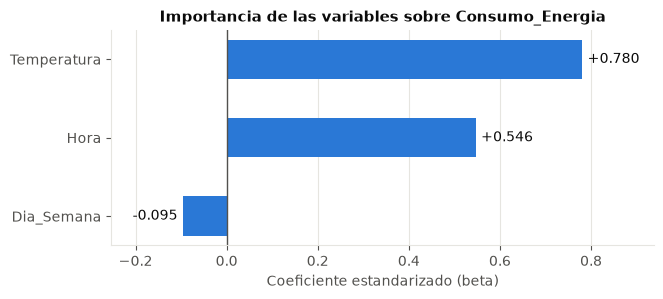

Variable de mayor impacto: Temperatura


In [15]:
orden = betas.abs().sort_values().index
fig, ax = plt.subplots(figsize=(7, 2.8))
barras = ax.barh(orden, betas[orden], color=AZUL, height=0.5)
ax.bar_label(barras, labels=[f"{v:+.3f}" for v in betas[orden]], padding=4, color=TEXTO)
ax.axvline(0, color=TEXTO_SEC, linewidth=1)
ax.margins(x=0.18)
ax.grid(axis="y", visible=False)
ax.set_xlabel("Coeficiente estandarizado (beta)")
ax.set_title(f"Importancia de las variables sobre {OBJETIVO}")
guardar(fig, "importancia")
plt.show()

print("Variable de mayor impacto:", betas.abs().idxmax())

In [16]:
# Interpretación automática a partir de los resultados obtenidos
UNIDADES_X = {'Temperatura': 'grado Celsius', 'Hora': 'hora', 'Dia_Semana': 'día de avance en la semana'}
for var in VARIABLES:
    c, p = coeficientes[var], ols.pvalues[var]
    sentido = "aumenta" if c > 0 else "disminuye"
    conclusion = "es estadísticamente significativa" if p < 0.05 else "NO es estadísticamente significativa"
    print(f"- {var}: por cada {UNIDADES_X[var]} adicional, {OBJETIVO} {sentido} en promedio "
          f"{abs(c):,.4f} {UNIDAD_Y}, manteniendo constantes las demás variables. "
          f"p-valor {fmt_p(p)}: {conclusion} al 5 %.")

- Temperatura: por cada grado Celsius adicional, Consumo_Energia aumenta en promedio 9.9529 kWh, manteniendo constantes las demás variables. p-valor < 0.001: es estadísticamente significativa al 5 %.
- Hora: por cada hora adicional, Consumo_Energia aumenta en promedio 5.0198 kWh, manteniendo constantes las demás variables. p-valor < 0.001: es estadísticamente significativa al 5 %.
- Dia_Semana: por cada día de avance en la semana adicional, Consumo_Energia disminuye en promedio 3.0312 kWh, manteniendo constantes las demás variables. p-valor < 0.001: es estadísticamente significativa al 5 %.


**Interpretación de los coeficientes**

Ecuación: `Consumo_Energia = 101.29 + 9.953·Temperatura + 5.020·Hora − 3.031·Dia_Semana`

- **Intercepto (101.29):** consumo base de la ecuación cuando las variables valen cero; no tiene interpretación práctica directa (no existe la hora 0 ni el día 0).
- **Temperatura (+9.953, p < 0.001):** cada grado Celsius adicional aumenta el consumo en promedio **9.95 kWh**, a igual hora y día. Es coherente con un mayor uso de aire acondicionado y refrigeración.
- **Hora (+5.020, p < 0.001):** cada hora que avanza el día el consumo sube en promedio **5.02 kWh**.
- **Dia_Semana (−3.031, p < 0.001):** al avanzar un día en la semana el consumo baja en promedio **3.03 kWh**; el domingo se consumen unos 18 kWh menos que el lunes (6 × 3.03).

Las tres variables son **estadísticamente significativas**.

### ¿Qué variable tiene mayor impacto en el consumo de energía?

| Variable | Coef. estandarizado | Efecto de 1 desviación estándar |
|---|---|---|
| `Temperatura` | **0.780** | +49.7 kWh |
| `Hora` | 0.546 | +34.8 kWh |
| `Dia_Semana` | −0.095 | −6.1 kWh |

**La `Temperatura`.** Tiene el mayor coeficiente estandarizado (0.780) y la mayor correlación con el consumo (0.772). La `Hora` es la segunda en importancia (0.546) y `Dia_Semana` influye poco (−0.095), aunque su efecto sí es significativo.

### 5.4 Valores reales vs. predichos

Figura guardada: informe/figuras/energia_real_vs_predicho.png


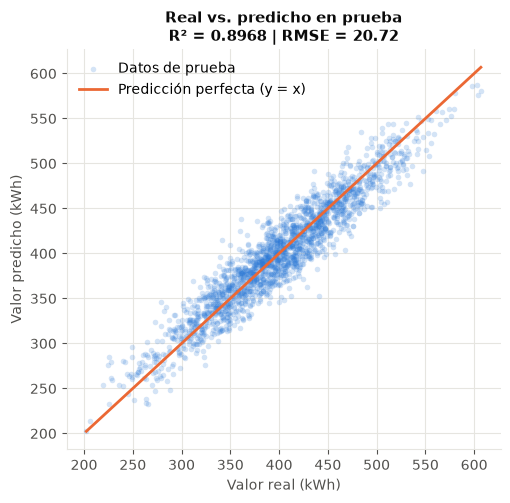

In [17]:
alfa_test = max(0.2, min(0.7, 300 / len(y_test)))
fig, ax = plt.subplots(figsize=(5.6, 5.2))
ax.scatter(y_test, pred_test, s=16, color=AZUL, alpha=alfa_test, linewidths=0, label="Datos de prueba")
limites = [min(y_test.min(), pred_test.min()), max(y_test.max(), pred_test.max())]
ax.plot(limites, limites, color=NARANJA, linewidth=2, label="Predicción perfecta (y = x)")
ax.set_xlabel(f"Valor real ({UNIDAD_Y})")
ax.set_ylabel(f"Valor predicho ({UNIDAD_Y})")
ax.set_title(f"Real vs. predicho en prueba\nR² = {metricas['prueba']['R2']:.4f} | RMSE = {metricas['prueba']['RMSE']:.2f}")
ax.legend(loc="upper left")
guardar(fig, "real_vs_predicho")
plt.show()

### 5.5 Análisis de residuos

Figura guardada: informe/figuras/energia_residuos.png


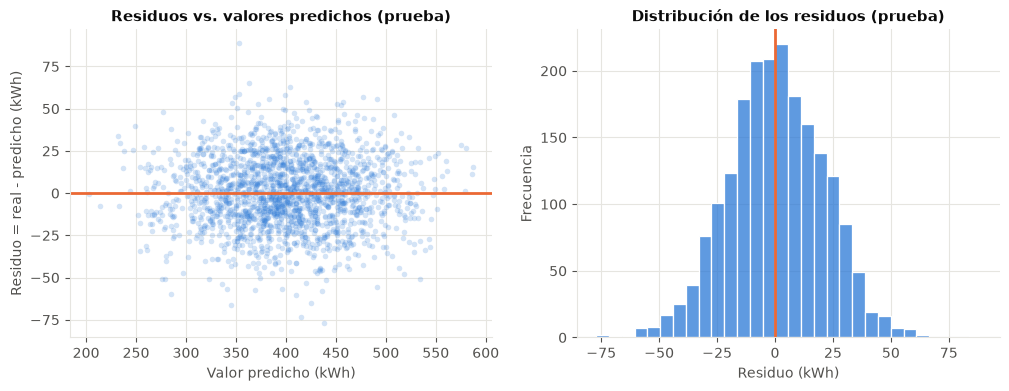

Media de los residuos: 0.448 | Desviación estándar: 20.725


In [18]:
residuos = y_test - pred_test
fig, (ax1, ax2) = plt.subplots(1, 2, figsize=(12, 4))
ax1.scatter(pred_test, residuos, s=16, color=AZUL, alpha=alfa_test, linewidths=0)
ax1.axhline(0, color=NARANJA, linewidth=2)
ax1.set_xlabel(f"Valor predicho ({UNIDAD_Y})")
ax1.set_ylabel(f"Residuo = real - predicho ({UNIDAD_Y})")
ax1.set_title("Residuos vs. valores predichos (prueba)")
sns.histplot(residuos, bins=30, color=AZUL, edgecolor="white", ax=ax2)
ax2.axvline(0, color=NARANJA, linewidth=2)
ax2.set_xlabel(f"Residuo ({UNIDAD_Y})")
ax2.set_ylabel("Frecuencia")
ax2.set_title("Distribución de los residuos (prueba)")
guardar(fig, "residuos")
plt.show()

print(f"Media de los residuos: {residuos.mean():.3f} | Desviación estándar: {residuos.std():.3f}")

**Lectura de las gráficas de evaluación**

- En *real vs. predicho* los puntos se agrupan alrededor de la diagonal en todo el rango de consumo.
- Los residuos se reparten alrededor de cero, sin curvas ni embudos, y su histograma es simétrico con forma de campana: el modelo lineal describe bien estos datos.

## 6. Análisis adicional: la hora es una variable cíclica

El enunciado indica que la `Hora` va de 1 a 24 y es **cíclica**: después de la hora 24 viene la hora 1. El modelo principal la trata como un número cualquiera, de modo que para él la hora 24 y la hora 1 son los valores más alejados posibles, cuando en el reloj son vecinas.

Una forma habitual de representar una variable cíclica es reemplazarla por dos columnas:

$$Hora\_sen = \sin\left(\frac{2\pi \cdot Hora}{24}\right), \qquad Hora\_cos = \cos\left(\frac{2\pi \cdot Hora}{24}\right)$$

Así cada hora queda ubicada sobre un círculo y la 24 queda junto a la 1. A continuación se compara el modelo principal con dos versiones alternativas, usando exactamente la misma división 80/20. **Esto es un análisis adicional: el modelo principal no se reemplaza.**

In [19]:
# Codificación cíclica de la hora: la hora 24 y la hora 1 quedan como vecinas
df_c = df.copy()
df_c["Hora_sen"] = np.sin(2 * np.pi * df_c["Hora"] / 24)
df_c["Hora_cos"] = np.cos(2 * np.pi * df_c["Hora"] / 24)

versiones = {
    "A. Principal (Hora lineal)": VARIABLES,
    "B. Hora como seno/coseno": ["Temperatura", "Dia_Semana", "Hora_sen", "Hora_cos"],
    "C. Hora lineal + seno/coseno": ["Temperatura", "Hora", "Dia_Semana", "Hora_sen", "Hora_cos"],
}
comparacion, modelos_c, p_valores_c = {}, {}, {}
for nombre_v, cols in versiones.items():
    # Misma semilla y mismas filas: la división es idéntica a la del modelo principal
    Xc_train, Xc_test, yc_train, yc_test = train_test_split(df_c[cols], df_c[OBJETIVO], test_size=0.2, random_state=SEMILLA)
    m = LinearRegression().fit(Xc_train, yc_train)
    modelos_c[nombre_v] = (m, cols)
    p_valores_c[nombre_v] = sm.OLS(yc_train, sm.add_constant(Xc_train)).fit().pvalues.drop("const")
    mt, mp = calcular_metricas(yc_train, m.predict(Xc_train)), calcular_metricas(yc_test, m.predict(Xc_test))
    comparacion[nombre_v] = {"RMSE entrenamiento": mt["RMSE"], "R2 entrenamiento": mt["R2"],
                             "RMSE prueba": mp["RMSE"], "R2 prueba": mp["R2"]}
comparacion = pd.DataFrame(comparacion).T
print("p-valores de los términos de la hora en la versión C:")
print(p_valores_c["C. Hora lineal + seno/coseno"][["Hora", "Hora_sen", "Hora_cos"]].map(lambda p: "p " + fmt_p(p)).to_string())
comparacion

p-valores de los términos de la hora en la versión C:
Hora        p < 0.001
Hora_sen    p = 0.905
Hora_cos    p = 0.120


,RMSE entrenamiento,R2 entrenamiento,RMSE prueba,R2 prueba
A. Principal (Hora lineal),19.9798,0.9015,20.7248,0.8968
B. Hora como seno/coseno,29.4611,0.7857,29.9066,0.7851
C. Hora lineal + seno/coseno,19.9768,0.9015,20.7260,0.8968


Figura guardada: informe/figuras/energia_hora_ciclica.png


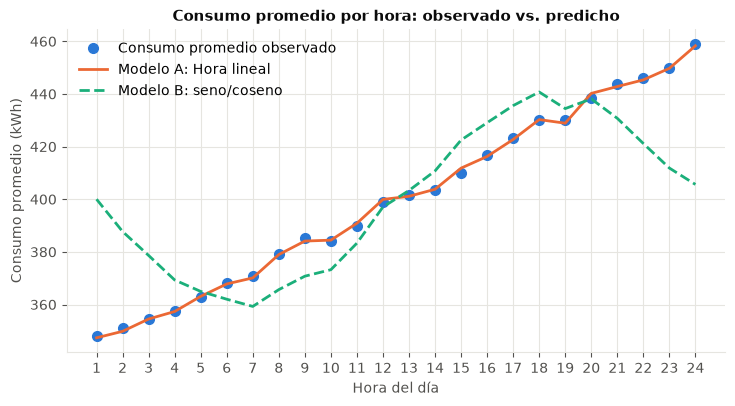

Consumo promedio observado: hora 1 = 348.0 kWh | hora 24 = 459.1 kWh


In [20]:
# Consumo promedio por hora: observado frente a lo que predice cada versión
por_hora = df_c.groupby("Hora")[OBJETIVO].mean()
pred_a = df_c.assign(p=modelos_c["A. Principal (Hora lineal)"][0].predict(df_c[VARIABLES])).groupby("Hora")["p"].mean()
cols_b = modelos_c["B. Hora como seno/coseno"][1]
pred_b = df_c.assign(p=modelos_c["B. Hora como seno/coseno"][0].predict(df_c[cols_b])).groupby("Hora")["p"].mean()

fig, ax = plt.subplots(figsize=(8.5, 4.2))
ax.plot(por_hora.index, por_hora.values, "o", color=AZUL, markersize=7, label="Consumo promedio observado")
ax.plot(pred_a.index, pred_a.values, color=NARANJA, linewidth=2, label="Modelo A: Hora lineal")
ax.plot(pred_b.index, pred_b.values, color=AQUA, linewidth=2, linestyle="--", label="Modelo B: seno/coseno")
ax.set_xticks(range(1, 25))
ax.set_xlabel("Hora del día")
ax.set_ylabel("Consumo promedio (kWh)")
ax.set_title("Consumo promedio por hora: observado vs. predicho")
ax.legend(loc="upper left")
guardar(fig, "hora_ciclica")
plt.show()

print(f"Consumo promedio observado: hora 1 = {por_hora[1]:.1f} kWh | hora 24 = {por_hora[24]:.1f} kWh")

**Resultado de la comparación**

| Versión | RMSE prueba | R² prueba |
|---|---|---|
| A. Principal (Hora lineal) | **20.72** | **0.8968** |
| B. Hora como seno/coseno | 29.91 | 0.7851 |
| C. Hora lineal + seno/coseno | 20.73 | 0.8968 |

- **La versión con seno/coseno (B) es peor**, no mejor: el RMSE sube de 20.72 a 29.91 kWh y el R² baja de 0.897 a 0.785.
- **La razón está en los datos.** La gráfica muestra que el consumo promedio crece casi en línea recta desde la hora 1 (348 kWh) hasta la hora 24 (459 kWh) y luego cae de golpe al volver a la hora 1. El seno/coseno obliga a que la hora 24 y la hora 1 tengan consumos parecidos, y eso no ocurre en este dataset.
- **Agregar seno/coseno al modelo principal (C) no aporta nada:** las métricas son iguales a las de A y los términos nuevos no son significativos (p = 0.905 para el seno y p = 0.120 para el coseno).

**Conclusión.** Aunque en teoría la hora es cíclica, y con datos reales de consumo la codificación seno/coseno suele ser la apropiada, en estos datos la relación entre hora y consumo es lineal. Por eso se mantiene el modelo principal (A), que además es el que pide el enunciado.

## 7. Despliegue: exportación del modelo

El modelo entrenado se guarda en disco para usarlo después en la interfaz web sin volver a entrenar. Se exporta en dos formatos:

- **`.pkl` (pickle):** módulo estándar de Python para serializar cualquier objeto.
- **`.joblib` (joblib):** librería recomendada por scikit-learn; es más eficiente con objetos que contienen arreglos grandes de NumPy.

Junto con el modelo se guardan los nombres de las variables, las métricas y los rangos de los datos, que la aplicación usa para validar las entradas.

In [21]:
paquete = {
    "modelo": modelo,
    "ejercicio": "Energía",
    "variables": VARIABLES,
    "objetivo": OBJETIVO,
    "unidad_objetivo": UNIDAD_Y,
    "etiquetas": ETIQUETAS,
    "intercepto": float(modelo.intercept_),
    "coeficientes": {v: float(c) for v, c in coeficientes.items()},
    "coef_estandarizados": {v: float(b) for v, b in betas.items()},
    "p_valores": {v: float(ols.pvalues[v]) for v in VARIABLES},
    "ic95": {v: [float(ic.loc[v, 0]), float(ic.loc[v, 1])] for v in VARIABLES},
    "ecuacion": ecuacion,
    "metricas": {k: {m: float(x) for m, x in d.items()} for k, d in metricas.items()},
    "rangos": {c: {"min": float(df[c].min()), "max": float(df[c].max()), "media": float(df[c].mean())}
               for c in df.columns},
    "limites_validos": {'Temperatura': [-50, 60], 'Hora': [1, 24], 'Dia_Semana': [1, 7]},
    "variables_enteras": ['Hora', 'Dia_Semana'],
    "n_entrenamiento": len(X_train),
    "n_prueba": len(X_test),
    "random_state": SEMILLA,
    "version_sklearn": sklearn.__version__,
}

ruta_joblib = MODELOS / f"modelo_{NOMBRE}.joblib"
ruta_pkl = MODELOS / f"modelo_{NOMBRE}.pkl"

joblib.dump(paquete, ruta_joblib)              # joblib
with open(ruta_pkl, "wb") as f:                # pickle
    pickle.dump(paquete, f)

# Metadatos legibles (sin el modelo) para el informe
metadatos = {k: v for k, v in paquete.items() if k != "modelo"}
metadatos["correlaciones_objetivo"] = {v: float(corr.loc[v, OBJETIVO]) for v in VARIABLES}
metadatos["atipicos_iqr"] = {c: int(n) for c, n in atipicos.items()}
metadatos["extra"] = {
    "comparacion_hora": {k: {m: float(x) for m, x in fila.items()} for k, fila in comparacion.iterrows()},
    "p_valores_version_c": {k: float(v) for k, v in p_valores_c["C. Hora lineal + seno/coseno"].items()},
    "consumo_promedio_hora_1": float(por_hora[1]),
    "consumo_promedio_hora_24": float(por_hora[24]),
}
with open(MODELOS / f"metadatos_{NOMBRE}.json", "w", encoding="utf-8") as f:
    json.dump(metadatos, f, indent=2, ensure_ascii=False)

# Comprobación: los modelos cargados predicen igual que el original
cargado_joblib = joblib.load(ruta_joblib)
with open(ruta_pkl, "rb") as f:
    cargado_pkl = pickle.load(f)
assert np.allclose(cargado_joblib["modelo"].predict(X_test), pred_test)
assert np.allclose(cargado_pkl["modelo"].predict(X_test), pred_test)
print("Modelos guardados y verificados:")
for ruta in (ruta_joblib, ruta_pkl):
    print(f"  {ruta.relative_to(BASE)}  ({ruta.stat().st_size} bytes)")

Modelos guardados y verificados:
  modelos/modelo_energia.joblib  (2155 bytes)
  modelos/modelo_energia.pkl  (1875 bytes)


In [22]:
# Ejemplo de uso del modelo cargado con valores nuevos
ejemplo = pd.DataFrame([{'Temperatura': 25.0, 'Hora': 12, 'Dia_Semana': 3}])
prediccion = cargado_joblib["modelo"].predict(ejemplo[cargado_joblib["variables"]])[0]
print("Entrada:", ejemplo.to_dict("records")[0])
print(f"Predicción de {OBJETIVO}: {prediccion:,.2f} {UNIDAD_Y}")

Entrada: {'Temperatura': 25.0, 'Hora': 12, 'Dia_Semana': 3}
Predicción de Consumo_Energia: 401.25 kWh


## 8. Conclusiones del ejercicio

1. El modelo predice el consumo con **RMSE = 20.72 kWh y R² = 0.8968** en prueba, un error cercano al 5 % del consumo medio.
2. **La `Temperatura` es la variable de mayor impacto** (coeficiente estandarizado 0.780): cada grado adicional aumenta el consumo en 9.95 kWh.
3. La `Hora` es la segunda variable (0.546; +5.02 kWh por hora) y `Dia_Semana` tiene un efecto pequeño pero significativo (−3.03 kWh por día).
4. No hay sobreajuste.
5. **Sobre la hora cíclica:** conceptualmente la hora es circular, pero en este dataset el consumo crece de forma lineal de la hora 1 a la 24, por lo que la codificación seno/coseno empeora el ajuste (R² 0.785 frente a 0.897) y el modelo principal con la hora lineal es el más adecuado para estos datos.